/var/folders/8w/wrhpqbtj0k97t_2pqp7jpyvc0000gn/T/ipykernel_48522/1868330656.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("viridis")


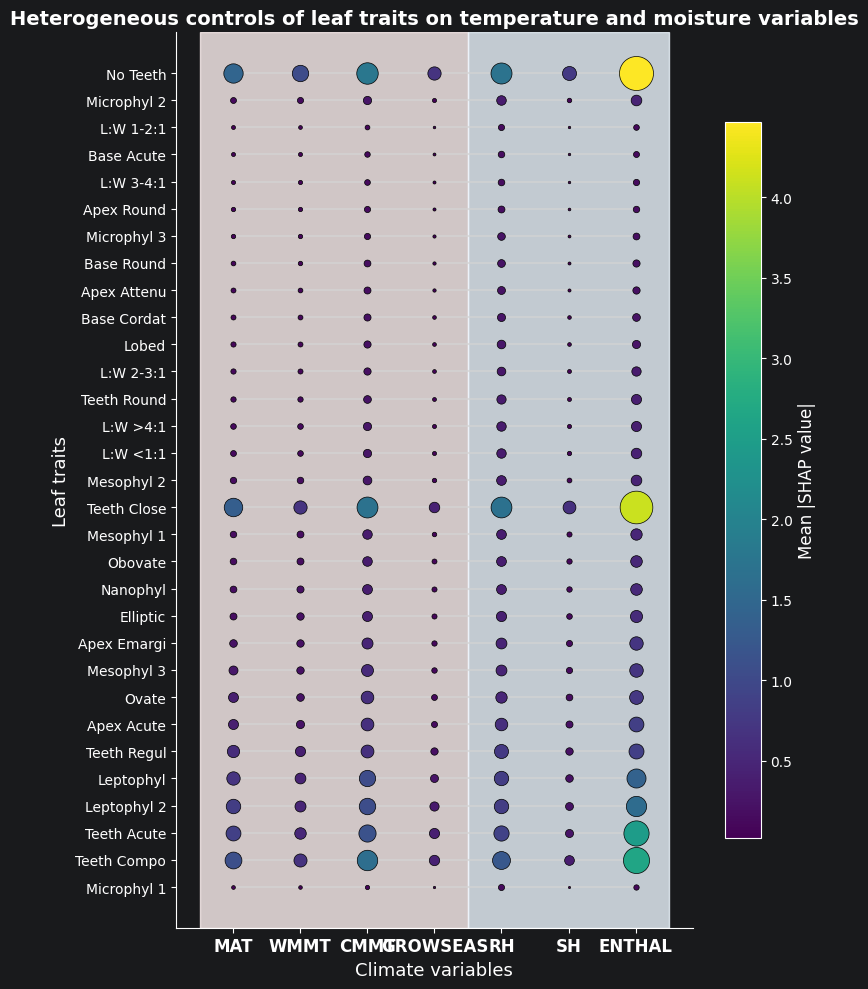

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap

# ========= 读数据 ==========
df = pd.read_excel(
    "importance.xlsx",
    index_col=0
)

# 去掉全为0的行
df = df.loc[(df != 0).any(axis=1)]

# 按出现次数排序（推荐）
freq = (df > 0).sum(axis=1)
df["freq"] = freq

df = df.sort_values(
    ["freq"],
    ascending=False
)

df = df.drop(columns="freq")

# ========= 坐标 ==========
variables = list(df.columns)
features = list(df.index)

x = np.arange(len(variables))
y = np.arange(len(features))

# ========= 颜色 ==========
cmap = get_cmap("viridis")

vmin = df[df > 0].min().min()
vmax = df.max().max()

# ========= Figure ==========
fig, ax = plt.subplots(
    figsize=(8,10)
)

# ========= 背景 ==========
# Temperature
ax.axvspan(
    -0.5,
    3.5,
    color="#FFF2F2",
    alpha=0.8
)

# Moisture
ax.axvspan(
    3.5,
    6.5,
    color="#EEF7FF",
    alpha=0.8
)

# ========= 循环每个 feature ==========
for i, feature in enumerate(features):

    vals = df.loc[feature].values

    idx = np.where(vals > 0)[0]

    if len(idx) == 0:
        continue

    # 横向连接线
    ax.hlines(
        y=i,
        xmin=idx.min(),
        xmax=idx.max(),
        color="lightgray",
        linewidth=1.5,
        alpha=0.7,
        zorder=1
    )

    # 点
    for j in idx:

        value = vals[j]

        size = value/vmax*600

        color = cmap(
            (value-vmin)/(vmax-vmin)
        )

        ax.scatter(
            j,
            i,
            s=size,
            color=color,
            edgecolor='black',
            linewidth=0.5,
            zorder=3
        )

# ========= 坐标 ==========
ax.set_xticks(x)
ax.set_xticklabels(
    variables,
    fontsize=12,
    fontweight='bold'
)

ax.set_yticks(y)
ax.set_yticklabels(
    features,
    fontsize=10
)

# 翻转y轴
ax.invert_yaxis()

# ========= 美化 ==========
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel(
    "Climate variables",
    fontsize=13
)

ax.set_ylabel(
    "Leaf traits",
    fontsize=13
)

ax.set_title(
    "Heterogeneous controls of leaf traits on temperature and moisture variables",
    fontsize=14,
    weight='bold'
)

# ========= colorbar ==========
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=plt.Normalize(
        vmin=vmin,
        vmax=vmax
    )
)

cbar = plt.colorbar(
    sm,
    ax=ax,
    shrink=0.8
)

cbar.set_label(
    "Mean |SHAP value|",
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    "Figure8_LollipopHeatmap.svg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()